# Groupes & automates — le problème du mot par automates finis

**Partie 5 — Frontières**

[← Partie 5](README.md) | [↑ Search](../README.md) | [Version Python](Frontieres-12-WordProblem-Automata-Python.ipynb) | [<< Frontieres-11 Abstraction à dette](Frontieres-11-Abstraction-Dette-ShortestPath-CSharp.ipynb) | [>> Frontieres-13 Approximation](Frontieres-13-Approximation-Guarantee-Audit-Python.ipynb)

> *Word processing in groups* (Epstein, Cannon, Holt, Levy, Paterson, Thurston, 1992) pose une question qui semble purement algébrique : deux mots dans les générateurs d'un groupe représentent-ils le même élément ? Ce carnet la rend **calculable** sur deux groupes témoins — le réseau `Z²` et le groupe libre `F₂` — en **construisant**, et non en invoquant, les **automates finis** qui reconnaissent les mots géodésiques, puis en **mesurant** l'écart entre une exploration BFS du graphe de Cayley (coût quadratique) et l'évaluation d'un automate (coût linéaire).

**Le fil** :
1. **Formes normales** — réduire un mot de `Z²` en `(i, j)`, un mot de `F₂` par annulation libre.
2. **Automates de géodésique** — construire l'automate à 9 états de `Z²` et celui à 5 états de `F₂`, et **affirmer par les propriétés** qu'ils sont corrects.
3. **Le contraste** — BFS (balle de rayon `R` = `2R²+2R+1` nœuds) vs automate (`|mot|` pas) sur des rayons croissants.
4. **Croissance** — compter les sphères : polynôme de degré 2 pour `Z²`, exponentielle de base 3 pour `F₂`.

**Alphabet** : `a`, `A` (=`a⁻¹`), `b`, `B` (=`b⁻¹`). Un mot est une chaîne de ces lettres.

In [1]:
// Imports et graine : les tirages du carnet (mots) doivent être
// reproductibles d'une exécution à l'autre.
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Text;
using Microsoft.DotNet.Interactive.Formatting;

var invariant = CultureInfo.InvariantCulture;
var parite = new Dictionary<string, (int Comparaisons, int Ecarts)>(StringComparer.Ordinal);

// Enregistrer chaque comparaison avant de lever en cas d'écart.
void Verifier<T>(string section, string cas, T calcule, T attendu)
{
    parite.TryGetValue(section, out var bilan);
    bool conforme = EqualityComparer<T>.Default.Equals(calcule, attendu);
    parite[section] = (bilan.Comparaisons + 1, bilan.Ecarts + (conforme ? 0 : 1));
    if (!conforme)
        throw new InvalidOperationException(FormattableString.Invariant(
            $"ÉCART — {section}, {cas} : calculé = {calcule} ; attendu = {attendu}."));
}

// Graine unique pour System.Random : même graine => mêmes échantillons d'une exécution C# à l'autre.
const int SEED = 7;
Verifier("Graine", "graine affichée dans le carnet Python", SEED, 7);
Console.WriteLine($"System.Random -- seed {SEED.ToString(invariant)}");

System.Random -- seed 7


## Deux groupes témoins

| Groupe | Générateurs | Relations | Un mot code |
|---|---|---|---|
| **`Z²`** | `a`, `b` | `ab = ba` (commutatif) | le point `(i, j)` du réseau, `i` = nombre net de `a`, `j` = nombre net de `b` |
| **`F₂`** | `a`, `b` | aucune (groupe libre) | un mot **librement réduit** (plus aucune paire `x x⁻¹` adjacente) |

Le **problème du mot** : un mot représente-t-il l'élément neutre ? Pour `Z²` : sa forme normale est-elle `(0, 0)` ? Pour `F₂` : sa réduction libre est-elle vide ?

Un mot est **géodésique** s'il est le *plus court* mot représentant son élément. C'est la propriété que les automates vont reconnaître.

### Réduire, c'est appliquer les relations

Avant de parler de géodésie, il faut un **oracle de réduction** : transformer n'importe quel mot en sa forme normale. Les fonctions `ReduceZ2` et `ReduceF2` appliquent mécaniquement les règles du groupe :

- **`Z²`** : commuter (tout `b` passe derrière tout `a`) puis annuler chaque paire `a A` — le résultat est la paire d'exposants `(i, j)`.
- **`F₂`** : annuler, en boucle, toute paire **adjacente** `x x⁻¹` — le résultat est le mot **librement réduit**.

Cet oracle est la brique commune de tout le carnet : « même élément » se décide **par la forme normale**, et « géodésique » se décide par la **longueur** de cette forme normale. Automates, BFS et croissance reposent tous sur ce point.

In [2]:
// Alphabet, inverses et formes normales
var INV = new Dictionary<char, char> { ['a'] = 'A', ['A'] = 'a', ['b'] = 'B', ['B'] = 'b' }; // inverse de chaque lettre
var GLYPH = new Dictionary<char, string> { ['a'] = "a", ['A'] = "a⁻¹", ['b'] = "b", ['B'] = "b⁻¹" }; // affichage

// Rendu lisible d'un mot : "aA" -> "a a⁻¹".
string Fmt(string word) => word.Length == 0 ? "(vide)" : string.Join(" ", word.Select(c => GLYPH[c]));

// Forme normale dans Z^2 : (i, j) = (nombre net de a, nombre net de b).
(int I, int J) ReduceZ2(string word)
{
    int i = word.Sum(c => c == 'a' ? 1 : c == 'A' ? -1 : 0);
    int j = word.Sum(c => c == 'b' ? 1 : c == 'B' ? -1 : 0);
    return (i, j);
}

// Réduction libre dans F_2 : annuler chaque paire adjacente x x^-1 à l'aide d'une pile.
string ReduceF2(string word)
{
    var pile = new Stack<char>();
    foreach (char c in word)
    {
        if (pile.Count > 0 && pile.Peek() == INV[c])
            pile.Pop();
        else
            pile.Push(c);
    }
    return new string(pile.Reverse().ToArray());
}

// Références citées : mots affichés, couples et réductions de la cellule Python correspondante.
var exemplesZ2 = new (string Mot, string Rendu, (int I, int J) Normale)[]
{
    ("aAb", "a a⁻¹ b", (0, 1)),
    ("aabBb", "a a b b⁻¹ b", (2, 1)),
    ("bbAa", "b b a⁻¹ a", (0, 2))
};
var exemplesF2 = new (string Mot, string Rendu, string Reduit, string RenduReduit)[]
{
    ("aAbb", "a a⁻¹ b b", "bb", "b b"),
    ("abB", "a b b⁻¹", "a", "a"),
    ("bAaB", "b a⁻¹ a b⁻¹", "", "(vide)")
};

var lignesZ2 = new List<string>();
foreach (var test in exemplesZ2)
{
    var normale = ReduceZ2(test.Mot);
    string rendu = Fmt(test.Mot);
    Verifier("Formes normales", $"Z^2 : rendu de {test.Mot}", rendu, test.Rendu);
    Verifier("Formes normales", $"Z^2 : réduction de {test.Mot}", normale, test.Normale);
    lignesZ2.Add(FormattableString.Invariant($"('{rendu}', ({normale.I}, {normale.J}))"));
}
Console.WriteLine($"Z^2 : [{string.Join(", ", lignesZ2)}]");

var lignesF2 = new List<string>();
foreach (var test in exemplesF2)
{
    string reduit = ReduceF2(test.Mot);
    string rendu = Fmt(test.Mot);
    string renduReduit = Fmt(reduit);
    Verifier("Formes normales", $"F_2 : rendu de {test.Mot}", rendu, test.Rendu);
    Verifier("Formes normales", $"F_2 : réduction de {test.Mot}", reduit, test.Reduit);
    Verifier("Formes normales", $"F_2 : rendu de la réduction de {test.Mot}", renduReduit, test.RenduReduit);
    lignesF2.Add($"('{rendu}', '{renduReduit}')");
}
Console.WriteLine($"F_2 : [{string.Join(", ", lignesF2)}]");

Z^2 : [('a a⁻¹ b', (0, 1)), ('a a b b⁻¹ b', (2, 1)), ('b b a⁻¹ a', (0, 2))]


F_2 : [('a a⁻¹ b b', 'b b'), ('a b b⁻¹', 'a'), ('b a⁻¹ a b⁻¹', '(vide)')]


In [3]:
// Décider si un mot représente le neutre
bool IsIdentityZ2(string word) => ReduceZ2(word) == (0, 0);
bool IsIdentityF2(string word) => ReduceF2(word).Length == 0;

// Références citées : rendus et verdicts des quatre cas affichés dans la source Python.
var checks = new (string Label, string Mot, Func<string, bool> Decide, string Rendu, bool Verdict)[]
{
    ("Z^2, mot = neutre ?", "aAbB", IsIdentityZ2, "a a⁻¹ b b⁻¹", true),
    ("Z^2, mot != neutre ?", "ab", IsIdentityZ2, "a b", false),
    ("F_2, mot = neutre ?", "aAbB", IsIdentityF2, "a a⁻¹ b b⁻¹", true),
    ("F_2, mot != neutre ?", "ab", IsIdentityF2, "a b", false)
};
foreach (var test in checks)
{
    string rendu = Fmt(test.Mot);
    bool verdict = test.Decide(test.Mot);
    Verifier("Problème du mot", $"{test.Label} — rendu", rendu, test.Rendu);
    Verifier("Problème du mot", $"{test.Label} — verdict", verdict, test.Verdict);
    Console.WriteLine($"  {test.Label,-20} {rendu,-12} -> {verdict}");
}

// AFFIRMATION (pas de prose) : les formes normales sont stables sous les relations
var formeAb = ReduceZ2("ab");
var formeBa = ReduceZ2("ba");
Verifier("Formes normales", "commutativité dans Z^2", formeAb, formeBa);
Verifier("Formes normales", "exposants de ab dans Z^2", formeAb, (1, 1));
Verifier("Formes normales", "réduction libre de abBa", ReduceF2("abBa"), "aa");
Verifier("Formes normales", "annulation dans Z^2", IsIdentityZ2(new string('a', 5) + new string('A', 5)), true);
Verifier("Formes normales", "annulation dans F_2", IsIdentityF2(new string('a', 3) + new string('A', 3)), true);
Console.WriteLine("\n[PASS] formes normales coherentes (commutativite Z^2, reduction libre F_2)");

  Z^2, mot = neutre ?  a a⁻¹ b b⁻¹  -> True


  Z^2, mot != neutre ? a b          -> False


  F_2, mot = neutre ?  a a⁻¹ b b⁻¹  -> True


  F_2, mot != neutre ? a b          -> False



[PASS] formes normales coherentes (commutativite Z^2, reduction libre F_2)


### Pourquoi ce contraste porte le problème du mot

Le choix de ces deux groupes n'est pas anecdotique : il isole **ce qui gouverne le problème du mot**. Le problème du mot demande : ce mot représente-t-il l'élément neutre ? Réduire un mot, c'est appliquer les **relations** du groupe jusqu'à sa forme canonique.

- **`Z²`** a une relation — `ab = ba`. Réduire, c'est **commuter** puis **annuler** les paires `a A` : la forme normale est le point `(i, j)`, et deux mots codent le même point si et seulement si leurs exposants coïncident.
- **`F₂`** n'a **aucune** relation : seule l'annulation d'une paire adjacente `x x⁻¹` est licite. La forme normale est le mot librement réduit lui-même.

Le contraste n'est donc pas `Z²` contre `F₂`, c'est **avec relations** contre **sans relations** : c'est la présence de relations qui fait le coût, la structure, et — comme on va le mesurer — la régularité du langage géodésique.

## Les mots géodésiques forment un langage **régulier**

Un mot est géodésique s'il est le plus court représentant son élément.

- **Dans `Z²`**, un mot est géodésique ⟺ *toutes ses lettres `a` ont le même signe* **et** *toutes ses lettres `b` ont le même signe* (sinon une annulation `x x⁻¹` l'allongerait au-delà de `|i|+|j|`). On n'a donc qu'à se souvenir du signe **vu** pour `a` et du signe vu pour `b` : **3 × 3 = 9 états**.
- **Dans `F₂`**, un mot est géodésique ⟺ il est librement réduit, c'est-à-dire qu'aucune lettre n'annule la précédente. On n'a qu'à se souvenir de la **dernière lettre** : **5 états** (aucune, `a`, `A`, `b`, `B`).

Deux automates finis, **construits** ci-dessous — pas invoqués. Leur correction sera **affirmée par les propriétés** (accord avec l'oracle de géodésie sur des milliers de mots), pas en prose.

In [4]:
// Automate des mots geodesiques de Z^2 : 9 etats = (signe_a, signe_b), chacun dans {None, +, -}
var signesZ2 = new char?[] { null, '+', '-' };
var Z2_STATES = (from sa in signesZ2 from sb in signesZ2 select (A: sa, B: sb)).ToArray();
var SIGNA = new Dictionary<char, char> { ['a'] = '+', ['A'] = '-' };
var SIGNB = new Dictionary<char, char> { ['b'] = '+', ['B'] = '-' };

// Engager un signe : aucun signe -> signe lu ; même signe -> stable.
char CommitSign(char? current, char sign)
{
    if (current is null || current == sign)
        return sign;
    return 'x'; // conflit
}

// L'état initial est (None, None). Un conflit est un rejet, pas un dixième état.
(bool Accepte, int Pas) LireAutomateZ2(string word)
{
    char? sa = null, sb = null;
    int pas = 0;
    foreach (char c in word)
    {
        if (SIGNA.TryGetValue(c, out char signeA))
            sa = CommitSign(sa, signeA);
        else
            sb = CommitSign(sb, SIGNB[c]);
        if (sa == 'x' || sb == 'x')
            return (false, pas); // conflit de signe -> non geodesique
        pas++;
    }
    return (true, pas);
}
bool Z2GeoAccepts(string word) => LireAutomateZ2(word).Accepte;

string RenduEtat(char? valeur) => valeur is char c ? $"'{c}'" : "None";
string RenduEtatZ2((char? A, char? B) etat) => $"({RenduEtat(etat.A)}, {RenduEtat(etat.B)})";

// Références citées : effectif, états et lignes de la sortie Python.
const string sectionAutomateZ2 = "Automate Z²";
Verifier(sectionAutomateZ2, "nombre d'états", Z2_STATES.Length, 9);
Verifier(sectionAutomateZ2, "nombre d'états distincts", Z2_STATES.Distinct().Count(), 9);
string etatInitialZ2 = RenduEtatZ2(Z2_STATES[0]);
string etatPositifZ2 = RenduEtatZ2(Z2_STATES[4]);
string etatNegatifZ2 = RenduEtatZ2(Z2_STATES[^1]);
Verifier(sectionAutomateZ2, "état initial", etatInitialZ2, "(None, None)");
Verifier(sectionAutomateZ2, "état d'indice 4", etatPositifZ2, "('+', '+')");
Verifier(sectionAutomateZ2, "dernier état", etatNegatifZ2, "('-', '-')");
Console.WriteLine(FormattableString.Invariant($"etats de l'automate Z^2 : {Z2_STATES.Length}  (ex. {etatInitialZ2}, {etatPositifZ2}, {etatNegatifZ2})"));

var verdictsZ2 = new (string Mot, string Rendu, bool Verdict)[]
{
    ("aab", "a a b", true),
    ("aA", "a a⁻¹", false),
    ("abAB", "a b a⁻¹ b⁻¹", false),
    ("bba", "b b a", true),
    ("aAb", "a a⁻¹ b", false)
};
foreach (var exemple in verdictsZ2)
{
    string rendu = Fmt(exemple.Mot);
    bool verdict = Z2GeoAccepts(exemple.Mot);
    Verifier(sectionAutomateZ2, $"{exemple.Mot} — rendu", rendu, exemple.Rendu);
    Verifier(sectionAutomateZ2, $"{exemple.Mot} — verdict", verdict, exemple.Verdict);
    Console.WriteLine($"  {rendu,-14} -> geodesique ? {verdict}");
}

etats de l'automate Z^2 : 9  (ex. (None, None), ('+', '+'), ('-', '-'))


  a a b          -> geodesique ? True


  a a⁻¹          -> geodesique ? False


  a b a⁻¹ b⁻¹    -> geodesique ? False


  b b a          -> geodesique ? True


  a a⁻¹ b        -> geodesique ? False


In [5]:
// Automate des mots geodesiques de F_2 : 5 etats = derniere lettre vue (ou None)
var F2_STATES = new char?[] { null, 'a', 'A', 'b', 'B' };

bool F2GeoAccepts(string word)
{
    char? last = null;
    foreach (char c in word)
    {
        if (last is char precedente && precedente == INV[c])
            return false; // x x^-1 adjacent -> non librement reduit
        last = c;
    }
    return true;
}

// Références citées : effectif, liste ordonnée et verdicts de la sortie Python.
const string sectionAutomateF2 = "Automate F₂";
string renduEtatsF2 = "[" + string.Join(", ", F2_STATES.Select(RenduEtat)) + "]";
Verifier(sectionAutomateF2, "nombre d'états", F2_STATES.Length, 5);
Verifier(sectionAutomateF2, "liste ordonnée des états", renduEtatsF2, "[None, 'a', 'A', 'b', 'B']");
Console.WriteLine(FormattableString.Invariant($"etats de l'automate F_2 : {F2_STATES.Length}  {renduEtatsF2}"));

var verdictsF2 = new (string Mot, string Rendu, bool Verdict)[]
{
    ("ab", "a b", true),
    ("aA", "a a⁻¹", false),
    ("abBa", "a b b⁻¹ a", false),
    ("bA", "b a⁻¹", true),
    ("", "(vide)", true)
};
foreach (var exemple in verdictsF2)
{
    string rendu = Fmt(exemple.Mot);
    bool verdict = F2GeoAccepts(exemple.Mot);
    Verifier(sectionAutomateF2, $"{exemple.Rendu} — rendu", rendu, exemple.Rendu);
    Verifier(sectionAutomateF2, $"{exemple.Rendu} — verdict", verdict, exemple.Verdict);
    Console.WriteLine($"  {rendu,-14} -> geodesique ? {verdict}");
}

etats de l'automate F_2 : 5  [None, 'a', 'A', 'b', 'B']


  a b            -> geodesique ? True


  a a⁻¹          -> geodesique ? False


  a b b⁻¹ a      -> geodesique ? False


  b a⁻¹          -> geodesique ? True


  (vide)         -> geodesique ? True


In [6]:
// AFFIRMATION par les proprietes : l'automate et l'oracle de geodesie s'accordent.
// Oracle : un mot est geodesique ssa sa longueur = longueur de sa forme normale.
bool OracleGeoZ2(string word)
{
    var (i, j) = ReduceZ2(word);
    return word.Length == Math.Abs(i) + Math.Abs(j);
}
bool OracleGeoF2(string word) => ReduceF2(word).Length == word.Length;

var ALPHA = new[] { 'a', 'A', 'b', 'B' };

string RandomWord(Random rng, int length)
{
    var lettres = new char[length];
    for (int i = 0; i < length; i++)
        lettres[i] = ALPHA[rng.Next(ALPHA.Length)];
    return new string(lettres);
}

// Chaque mot est tiré une seule fois et partagé entre l'automate et l'oracle.
int Agree(Random rng, Func<string, bool> acceptor, Func<string, bool> oracle, int n, int maxlen)
{
    int accords = 0;
    for (int i = 0; i < n; i++)
    {
        string word = RandomWord(rng, rng.Next(0, maxlen + 1));
        if (acceptor(word) == oracle(word))
            accords++;
    }
    return accords;
}

// Un seul flux .NET, initialisé à 7, pour les deux lots successifs.
const int N = 20_000;
const int longueurMax = 12;
var rngMots = new Random(SEED);
int accordsZ2 = Agree(rngMots, Z2GeoAccepts, OracleGeoZ2, N, longueurMax);
int accordsF2 = Agree(rngMots, F2GeoAccepts, OracleGeoF2, N, longueurMax);
Console.WriteLine(FormattableString.Invariant($"Z^2 : automate == oracle sur {accordsZ2}/{N} mots aleatoires"));
Console.WriteLine(FormattableString.Invariant($"F_2 : automate == oracle sur {accordsF2}/{N} mots aleatoires"));

// Références citées : les deux scores Python sont 20000/20000 ; l'accord exigé est exact.
Verifier("Accord automate/oracle", "Z^2 : score affiché", (accordsZ2, N), (20_000, 20_000));
Verifier("Accord automate/oracle", "F_2 : score affiché", (accordsF2, N), (20_000, 20_000));
Verifier("Accord automate/oracle", "Z^2 : accord sur tout le lot", accordsZ2, N);
Verifier("Accord automate/oracle", "F_2 : accord sur tout le lot", accordsF2, N);
Console.WriteLine(FormattableString.Invariant($"\n[PASS] les deux automates sont corrects (accord {accordsZ2 / (double)N:0%} avec l'oracle, 2x{N} mots)"));

Z^2 : automate == oracle sur 20000/20000 mots aleatoires


F_2 : automate == oracle sur 20000/20000 mots aleatoires



[PASS] les deux automates sont corrects (accord 100% avec l'oracle, 2x20000 mots)


### Lecture — l'automate est l'oracle

La cellule précédente n'est pas un simple test de non-régression, c'est le **résultat** : sur tout le lot tiré, l'automate (9 états pour `Z²`, 5 pour `F₂`) et l'oracle de géodésie — qui compare la longueur du mot à celle de sa forme normale — **s'accordent mot pour mot**. Le langage des mots géodésiques n'est pas seulement régulier : il est **calculé** par un automate fini, et l'accord mesuré est la preuve que les deux descriptions coïncident.

Le nombre d'états est l'information : `Z²` en demande 9 (le signe engagé, séparément, pour `a` et pour `b`), `F₂` seulement 5 (la dernière lettre vue suffit, car il n'y a qu'une annulation possible). La **complexité du groupe** se lit dans la **taille de l'automate** qui le saisit — un fait que le contraste BFS/automate du paragraphe suivant rendra économique.

> **Note de parité.** `System.Random(7)` produit des tirages propres au C# : les mots ne sont pas ceux de Python, mais l'alphabet, les longueurs possibles (de 0 à 12 inclus) et les tailles des lots sont identiques. Le C# retrouve `20000/20000` pour chaque groupe. Cet accord vaut pour les lots testés ; la justification générale repose sur les critères de géodésie et les invariants d'état décrits plus haut. Les états comptés sont les états acceptants des automates partiels, sans état puits explicite. La sortie d'environnement Python cite les versions de NumPy et de Matplotlib ; le C# n'utilise pas ces bibliothèques.

## Le contraste — BFS vs automate

Pour décider qu'un mot est géodésique, deux stratégies :

- **BFS** sur le graphe de Cayley de `Z²` : on explore la balle de rayon `R` (tous les éléments à distance `≤ R`) pour établir que l'élément du mot n'apparaît qu'à sa vraie distance. La balle de rayon `R` du réseau contient `2R² + 2R + 1` points — le coût est **quadratique** en `R`.
- **Automate** : on lit le mot lettre par lettre dans l'automate à 9 états. Le coût est **`|mot|` = `R`** pas — **linéaire**, et indépendant de la taille de la balle.

Mesurons les deux sur des rayons croissants.

> Comme en Python, le tableau utilise le BFS effectif jusqu'au rayon 200 ; la valeur au rayon 500 est calculée par la formule de la balle.

In [7]:
// Compter les sommets visités par BFS et les pas de l’automate
int BfsBallZ2(int rayon)
{
    // Les quatre voisins correspondent aux pas a, A, b, B.
    var directions = new (int Di, int Dj)[] { (1, 0), (-1, 0), (0, 1), (0, -1) };
    var vus = new HashSet<(int, int)> { (0, 0) };
    var frontiere = new Queue<(int I, int J, int Dist)>(); // (i, j, dist)
    frontiere.Enqueue((0, 0, 0));
    while (frontiere.Count > 0)
    {
        var (i, j, dist) = frontiere.Dequeue();
        if (dist == rayon)
            continue;
        foreach (var (di, dj) in directions)
        {
            var voisin = (i + di, j + dj);
            if (vus.Add(voisin))
                frontiere.Enqueue((voisin.Item1, voisin.Item2, dist + 1));
        }
    }
    return vus.Count;
}

int BallZ2(int rayon) => 2 * rayon * rayon + 2 * rayon + 1;

// Références citées : les six lignes de la sortie Python, ratios au dixième.
var rayonsBfs = new[] { 10, 20, 50, 100, 200, 500 };
var referenceBfs = new (int Rayon, int Balle, int Pas, string Ratio)[]
{
    (10, 221, 10, "22.1"),
    (20, 841, 20, "42.0"),
    (50, 5_101, 50, "102.0"),
    (100, 20_201, 100, "202.0"),
    (200, 80_401, 200, "402.0"),
    (500, 501_001, 500, "1,002.0")
};
const string sectionBfs = "BFS / automate";
Verifier(sectionBfs, "nombre de lignes", rayonsBfs.Length, referenceBfs.Length);
Console.WriteLine($"{"R",4} | {"BFS (balle R)",14} | {"automate (pas)",15} | {"ratio BFS/automate",18}");
Console.WriteLine(new string('-', 58));
for (int k = 0; k < rayonsBfs.Length; k++)
{
    int rayon = rayonsBfs[k];
    var reference = referenceBfs[k];
    int balle = rayon <= 200 ? BfsBallZ2(rayon) : BallZ2(rayon); // BFS reel <= 200, formule au-dela
    string mot = new string('a', rayon); // mot geodesique de longueur R
    var (accepte, pas) = LireAutomateZ2(mot);
    // Au demi-dixième, départager au pair comme dans la sortie Python (42.05 -> 42.0).
    string ratio = Math.Round((decimal)balle / pas, 1, MidpointRounding.ToEven).ToString("N1", invariant);
    string cas = FormattableString.Invariant($"R = {rayon}");
    Verifier(sectionBfs, $"{cas} : rayon", rayon, reference.Rayon);
    Verifier(sectionBfs, $"{cas} : effectif de la balle", balle, reference.Balle);
    Verifier(sectionBfs, $"{cas} : mot accepté", accepte, true);
    Verifier(sectionBfs, $"{cas} : pas de l'automate", pas, reference.Pas);
    Verifier(sectionBfs, $"{cas} : ratio affiché", ratio, reference.Ratio);
    Console.WriteLine(FormattableString.Invariant($"{rayon,4} | {balle,14:N0} | {pas,15:N0} | {ratio,18}"));
}

// Cohérence : la balle obtenue par BFS coïncide avec la formule 2R^2+2R+1.
int balleBfs50 = BfsBallZ2(50);
Verifier(sectionBfs, "BFS(50) contre la formule", balleBfs50, BallZ2(50));
Verifier(sectionBfs, "BFS(50) contre la sortie Python", balleBfs50, 5_101);
Console.WriteLine(FormattableString.Invariant($"\n[PASS] balle BFS(50) = 2·50²+2·50+1 = {balleBfs50:N0}"));

   R |  BFS (balle R) |  automate (pas) | ratio BFS/automate


----------------------------------------------------------


  10 |            221 |              10 |               22.1


  20 |            841 |              20 |               42.0


  50 |          5,101 |              50 |              102.0


 100 |         20,201 |             100 |              202.0


 200 |         80,401 |             200 |              402.0


 500 |        501,001 |             500 |            1,002.0



[PASS] balle BFS(50) = 2·50²+2·50+1 = 5,101


## Croissance — polynôme vs exponentielle

On **compte** (on ne cite pas) les éléments par distance :

- **`Z²`** : la balle de rayon `R` a `2R² + 2R + 1` points — croissance **polynôme de degré 2** (le réseau est « maigre »).
- **`F₂`** : chaque mot géodésique de longueur `R−1` s'étend de **3** façons (toute lettre sauf l'inverse de la dernière) ; la balle de rayon `R` vaut `2·3^R − 1` — croissance **exponentielle de base 3** (le groupe libre « explode »).

La courbe ci-dessous (échelle log) rend l'écart visible : la droite exponentielle de `F₂` s'envole, la courbe polynôme de `Z²` s'aplatit.

sphères F₂ générées (r : nombre) : {0: '1', 1: '4', 2: '12', 3: '36', 4: '108', 5: '324', 6: '972', 7: '2,916', 8: '8,748', 9: '26,244'}


[PASS] sphères F₂ générées = 4·3^(r−1) pour r = 1..9


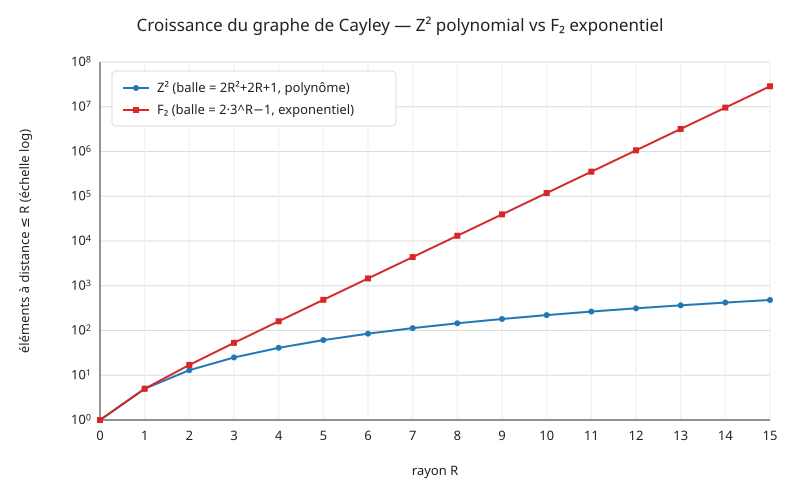

balle Z²(15) = 481   ·  balle F₂(15) = 28,697,813   (ratio 5.97e+04×)



Attestation de parité — écarts par section


CONFORME — Graine : 0 écart(s) sur 1 comparaison(s)


CONFORME — Formes normales : 0 écart(s) sur 20 comparaison(s)


CONFORME — Problème du mot : 0 écart(s) sur 8 comparaison(s)


CONFORME — Automate Z² : 0 écart(s) sur 15 comparaison(s)


CONFORME — Automate F₂ : 0 écart(s) sur 12 comparaison(s)


CONFORME — Accord automate/oracle : 0 écart(s) sur 4 comparaison(s)


CONFORME — BFS / automate : 0 écart(s) sur 33 comparaison(s)


CONFORME — Sphères F₂ : 0 écart(s) sur 30 comparaison(s)


CONFORME — Balles et figure : 0 écart(s) sur 54 comparaison(s)


In [8]:
// Générer les sphères, tracer les balles et attester la parité
long Puissance3(int exposant)
{
    long puissance = 1;
    for (int k = 0; k < exposant; k++)
        puissance = checked(puissance * 3);
    return puissance;
}
long BallF2(int rayon) => checked(2 * Puissance3(rayon) - 1);

// Controle : recompter les spheres F_2 par generation effective (petits R)
int[] F2SpheresByGeneration(int rayonMax)
{
    var effectifs = new int[rayonMax + 1];
    var mots = new List<string> { "" };
    effectifs[0] = mots.Count;
    for (int r = 1; r <= rayonMax; r++)
    {
        var suivants = new List<string>();
        foreach (string word in mots)
            foreach (char c in ALPHA)
                if (word.Length == 0 || c != INV[word[^1]])
                    suivants.Add(word + c);
        mots = suivants;
        effectifs[r] = mots.Count;
    }
    return effectifs;
}

// Références citées : effectifs affichés par Python pour les rayons 0 à 9.
const string sectionSpheres = "Sphères F₂";
var referenceSpheres = new[] { 1, 4, 12, 36, 108, 324, 972, 2_916, 8_748, 26_244 };
int[] spheresF2 = F2SpheresByGeneration(9);
Verifier(sectionSpheres, "nombre de rayons", spheresF2.Length, referenceSpheres.Length);
var lignesSpheres = new List<string>();
long cumulF2 = 0;
for (int r = 0; r < spheresF2.Length; r++)
{
    string cas = FormattableString.Invariant($"r = {r}");
    Verifier(sectionSpheres, $"{cas} : effectif Python", spheresF2[r], referenceSpheres[r]);
    if (r > 0)
        Verifier(sectionSpheres, $"{cas} : loi 4·3^(r−1)", (long)spheresF2[r], 4 * Puissance3(r - 1));
    cumulF2 += spheresF2[r];
    Verifier(sectionSpheres, $"{cas} : cumul des sphères contre balle", cumulF2, BallF2(r));
    lignesSpheres.Add(FormattableString.Invariant($"{r}: '{spheresF2[r]:N0}'"));
}
Console.WriteLine("sphères F₂ générées (r : nombre) : {" + string.Join(", ", lignesSpheres) + "}");
Console.WriteLine("[PASS] sphères F₂ générées = 4·3^(r−1) pour r = 1..9");

// Figure : croissance (balle) de Z^2 (polynome) vs F_2 (exponentielle), echelle log
int[] rayonsFigure = Enumerable.Range(0, 16).ToArray();
int[] ballesZ2 = rayonsFigure.Select(BallZ2).ToArray();
long[] ballesF2 = rayonsFigure.Select(BallF2).ToArray();

// Points de référence issus des formules et du domaine du tracé Python (r = 0..15).
var referenceBallesZ2 = new[] { 1, 5, 13, 25, 41, 61, 85, 113, 145, 181, 221, 265, 313, 365, 421, 481 };
var referenceBallesF2 = new long[] { 1, 5, 17, 53, 161, 485, 1_457, 4_373, 13_121, 39_365, 118_097, 354_293, 1_062_881, 3_188_645, 9_565_937, 28_697_813 };
const string sectionBalles = "Balles et figure";
Verifier(sectionBalles, "nombre de points Z²", ballesZ2.Length, referenceBallesZ2.Length);
Verifier(sectionBalles, "nombre de points F₂", ballesF2.Length, referenceBallesF2.Length);
for (int i = 0; i < rayonsFigure.Length; i++)
{
    string cas = FormattableString.Invariant($"r = {i}");
    Verifier(sectionBalles, $"{cas} : abscisse", rayonsFigure[i], i);
    Verifier(sectionBalles, $"{cas} : balle Z²", ballesZ2[i], referenceBallesZ2[i]);
    Verifier(sectionBalles, $"{cas} : balle F₂", ballesF2[i], referenceBallesF2[i]);
}

// Références citées : valeurs et ratio imprimés sous la figure Python.
int rayonFinal = rayonsFigure[^1];
int finaleZ2 = ballesZ2[^1];
long finaleF2 = ballesF2[^1];
string ratioFinal = ((double)finaleF2 / finaleZ2).ToString("0.00e+00", invariant);
Verifier(sectionBalles, "rayon final affiché", rayonFinal, 15);
Verifier(sectionBalles, "balle Z² finale affichée", finaleZ2, 481);
Verifier(sectionBalles, "balle F₂ finale affichée", finaleF2, 28_697_813L);
Verifier(sectionBalles, "ratio final affiché", ratioFinal, "5.97e+04");

// Le noyau reçoit le SVG lui-même, et non une chaîne échappée en HTML ou en texte.
class Graphique
{
    public Graphique(string svg) => Svg = svg;
    public string Svg { get; }
}
Formatter.Register<Graphique>((graphique, writer) => writer.Write(graphique.Svg), "image/svg+xml");

// Abscisse linéaire ; les graduations verticales sont espacées d'une décennie.
const int gauche = 100, droite = 770, haut = 62, bas = 420;
double XFigure(int rayon) => gauche + (droite - gauche) * rayon / (double)rayonFinal;
double YFigure(double balle) => bas - (bas - haut) * Math.Log10(balle) / 8.0;
var svgCroissance = new StringBuilder();
void LigneSvg(FormattableString ligne) => svgCroissance.AppendLine(ligne.ToString(invariant));
svgCroissance.AppendLine("<svg xmlns='http://www.w3.org/2000/svg' width='800' height='500' viewBox='0 0 800 500' role='img' aria-label='Croissance des balles de Z² et F₂ en échelle logarithmique'>");
svgCroissance.AppendLine("<rect width='800' height='500' fill='white'/><g font-family='sans-serif' font-size='13' fill='#222'>");
svgCroissance.AppendLine("<text x='400' y='31' text-anchor='middle' font-size='17'>Croissance du graphe de Cayley — Z² polynomial vs F₂ exponentiel</text>");
for (int decade = 0; decade <= 8; decade++)
{
    double y = YFigure(Math.Pow(10, decade));
    LigneSvg($"<line x1='{gauche}' y1='{y:0.###}' x2='{droite}' y2='{y:0.###}' stroke='#ddd'/>");
    LigneSvg($"<text x='{gauche - 9}' y='{y + 4:0.###}' text-anchor='end'>10<tspan baseline-shift='super' font-size='9'>{decade}</tspan></text>");
}
foreach (int rayon in rayonsFigure)
{
    double x = XFigure(rayon);
    LigneSvg($"<line x1='{x:0.###}' y1='{haut}' x2='{x:0.###}' y2='{bas}' stroke='#eee'/>");
    LigneSvg($"<text x='{x:0.###}' y='{bas + 20}' text-anchor='middle'>{rayon}</text>");
}
LigneSvg($"<path d='M {gauche} {haut} V {bas} H {droite}' fill='none' stroke='#333'/>");
svgCroissance.AppendLine("<text x='435' y='475' text-anchor='middle'>rayon R</text><text x='29' y='241' transform='rotate(-90 29 241)' text-anchor='middle'>éléments à distance ≤ R (échelle log)</text>");

void TracerSerie(IEnumerable<long> valeurs, string couleur, bool carres)
{
    var points = valeurs.Select((valeur, i) => (X: XFigure(rayonsFigure[i]), Y: YFigure(valeur))).ToArray();
    string coordonnees = string.Join(" ", points.Select(p => FormattableString.Invariant($"{p.X:0.###},{p.Y:0.###}")));
    LigneSvg($"<polyline points='{coordonnees}' fill='none' stroke='{couleur}' stroke-width='2'/>");
    foreach (var p in points)
    {
        if (carres)
            LigneSvg($"<rect x='{p.X - 3:0.###}' y='{p.Y - 3:0.###}' width='6' height='6' fill='{couleur}'/>");
        else
            LigneSvg($"<circle cx='{p.X:0.###}' cy='{p.Y:0.###}' r='3' fill='{couleur}'/>");
    }
}
TracerSerie(ballesZ2.Select(b => (long)b), "#1f77b4", false);
TracerSerie(ballesF2, "#d62728", true);
svgCroissance.AppendLine("<rect x='112' y='71' width='284' height='55' rx='4' fill='white' stroke='#ddd'/>");
svgCroissance.AppendLine("<path d='M 123 88 H 149' stroke='#1f77b4' stroke-width='2'/><circle cx='136' cy='88' r='3' fill='#1f77b4'/><text x='157' y='92'>Z² (balle = 2R²+2R+1, polynôme)</text>");
svgCroissance.AppendLine("<path d='M 123 110 H 149' stroke='#d62728' stroke-width='2'/><rect x='133' y='107' width='6' height='6' fill='#d62728'/><text x='157' y='114'>F₂ (balle = 2·3^R−1, exponentiel)</text></g></svg>");
display(new Graphique(svgCroissance.ToString()), "image/svg+xml");
Console.WriteLine(FormattableString.Invariant($"balle Z²({rayonFinal}) = {finaleZ2:N0}   ·  balle F₂({rayonFinal}) = {finaleF2:N0}   (ratio {ratioFinal}×)"));

// Le bilan exige des comparaisons exécutées dans chacune des sections du carnet.
var sectionsParite = new[] { "Graine", "Formes normales", "Problème du mot", sectionAutomateZ2, sectionAutomateF2, "Accord automate/oracle", "BFS / automate", sectionSpheres, sectionBalles };
Console.WriteLine("\nAttestation de parité — écarts par section");
foreach (string section in sectionsParite)
{
    if (!parite.TryGetValue(section, out var bilan) || bilan.Comparaisons <= 0 || bilan.Ecarts != 0)
        throw new InvalidOperationException($"Bilan de parité invalide : {section}.");
    Console.WriteLine(FormattableString.Invariant($"CONFORME — {section} : {bilan.Ecarts} écart(s) sur {bilan.Comparaisons} comparaison(s)"));
}

### Lecture du résultat

Le tableau BFS/automate et la courbe de croissance disent la même chose en deux registres :

- **Le coût de la géodésie n'est pas le coût de l'exploration.** Décider qu'un mot de `Z²` est géodésique coûte `R` pas dans l'automate, contre `2R²+2R+1` nœuds explorés par le BFS : le ratio croît comme `2R`. L'automate **comprime** la géométrie du réseau dans 9 états.
- **La croissance trahit la structure.** `Z²` est polynomial (degré 2) — son graphe de Cayley est « maigre » ; `F₂` est exponentiel (base 3) — il « explose ». Cette différence, **comptée** sur les sphères, est exactement ce que la régularité du langage géodésique encode : un automate fini ne « voit » que la structure locale, et c'est suffisant parce que la géodésie y est une propriété de **préfixe** (le signe engagé, la dernière lettre), pas une propriété globale.

C'est le sens opérationnel de *word processing* : là où l'algèbre « invoquait » un théorème, on **construit** la machine qui décide, et on **mesure** ce qu'elle épargne.

### Le coût, réparti entre la balle et le mot

Le contraste BFS/automate sépare deux coûts que l'on confond :

- **BFS** explore la **balle** de rayon `R` : son coût croît avec le nombre d'éléments à cette distance — quadratique en `R` pour `Z²`, **exponentielle** pour `F₂`. Décider la géodésie par BFS, c'est payer la croissance du groupe.
- **L'automate** lit le **mot** lettre par lettre : son coût est **linéaire en la longueur du mot**, quel que soit le groupe, quel que soit le rayon. Il ne construit jamais la balle.

C'est le payoff du framing « langage régulier » : la géodésie, qui vue comme exploration de la balle coûte le prix de la croissance, coûte **linéaire** une fois qu'on la reconnaît comme un langage fini à lire. Le tableau BFS/automate et la courbe de croissance ne disent pas deux choses : ils disent que le choix de la **représentation** (balle à explorer / automate à lire) décide du coût.

### « Régulier » ne veut pas dire « en général »

Il faut borner l'affirmation que ce carnet a établie. Les deux groupes témoins ont un problème du mot **décidable**, et un langage géodésique **régulier** : la réduction est algorithmique et l'automate est fini. Ce n'est **pas** la règle générale.

Un groupe présenté finiment peut avoir un problème du mot **indécidable** — il existe de tels groupes (Boone–Dehn, 1950) : aucun algorithme ne décide, pour un mot arbitraire, s'il représente l'élément neutre. « Automatique » (le langage des géodésiques est régulier) est donc une **propriété spéciale**, un privilège des groupes bien comportés comme `Z²` et `F₂`, pas le défaut des groupes finiment présentés.

La discipline de ce carnet — mesurer que l'automate et l'oracle coïncident — ne généralise qu'aux groupes où cette coïncidence est **vraie**. C'est précisément pourquoi elle est un **audit** : elle ne déclare pas la régularité, elle la **vérifie sur les groupes choisis**, et le lecteur doit savoir que d'autres groupes la refuseront.

## Exercice 1 — l'automate de `Z²` en une fonction

Complète `z2_geodesic_accepts` : elle doit renvoyer `true` si et seulement si le mot est géodésique dans `Z²`.

In [9]:
bool? z2_geodesic_accepts(string word)
{
    return null; // TODO etudiant
}

## Exercice 2 — l'automate de `F₂`

Complète `is_geodesic_f2` : renvoie `true` si et seulement si le mot est **librement réduit**.

In [10]:
bool? is_geodesic_f2(string word)
{
    return null; // TODO etudiant
}

## Exercice 3 — compter la croissance

Complète `growth_table` : pour le groupe donné (`"Z2"` ou `"F2"`), renvoie la liste `[balle(0), balle(1), ..., balle(max_r)]` — le nombre d'éléments à distance `≤ r` pour chaque rayon.

In [11]:
IReadOnlyList<long> growth_table(string group, int max_r)
{
    return Array.Empty<long>(); // TODO etudiant
}

## À retenir

| Groupe | Relations | Langage géodésique | Coût de la géodésie |
|---|---|---|---|
| `Z²` | `ab = ba` (commutatif) | régulier — 9 états | **linéaire** en le mot (automate) |
| `F₂` | aucune (libre) | régulier — 5 états | **linéaire** en le mot (automate) |

Trois faits tiennent le carnet. (1) Le **problème du mot** et la **géodésie** se décident par la **forme normale** — commutation + annulation pour `Z²`, annulation seule pour `F₂`. (2) Le langage des mots géodésiques est **régulier**, et l'automate qui le calcule **coïncide** avec l'oracle, mesure à l'appui. (3) Reconnaître cette régularité **change le coût** : de la croissance de la balle (quadratique / exponentielle, payée par le BFS) au **linéaire** en la longueur du mot (payée par l'automate).

Et une borne honnête : ces deux groupes sont **bien comportés**. Un groupe finiment présenté peut avoir un problème du mot **indécidable** (Boone–Dehn) — la régularité mesurée ici est un privilège, pas la règle.

> **Bilan de parité :** voir « Attestation de parité — écarts par section » sous la figure de croissance.

### Pour aller plus loin

- **Groupes « automatiques »** : les groupes **automatiques** (Epstein, Cannon, Thurston et al., 1992) sont ceux dont un langage régulier de formes normales satisfait la propriété des *compagnons de route* (fellow traveller property) — ce n'est pas « le langage géodésique est régulier ». `Z²` et `F₂` en sont deux exemples, et leurs langages géodésiques sont bien réguliers, comme le carnet vient de le construire. La croissance ne tranche pas la question : le théorème de Gromov identifie la croissance polynomiale aux groupes virtuellement nilpotents, mais le groupe de Heisenberg, nilpotent, n'est **pas** automatique (un groupe nilpotent ne l'est que s'il est virtuellement abélien). `F₂`, à croissance exponentielle, l'est. Piste ouverte : les **groupes hyperboliques**, où Cannon montre la régularité géodésique pour tout système générateur.
- **Retour à la série** : le BFS du bloc contraste est *exactement* la recherche non informée de [Search-2](../Part1-Foundations/README.md) ; l'automate est sa version **compressée** — la réduction d'espace que la série fait fil rouge, poussée jusqu'à l'état fini.
- **Le pont avec [Frontieres-11](Frontieres-11-Abstraction-Dette-ShortestPath-CSharp.ipynb)** : y comprimer un graphe à *dette bornée* ; ici compresser un groupe en *automate* — deux formes de la même idée : mesurer ce que la compression coûte.

[← Part5-Frontieres](README.md) · [↑ Search](../README.md)

> Source pédagogique : [Version Python](Frontieres-12-WordProblem-Automata-Python.ipynb).